# Heart Disease Prediction System

**Live Deployment (Cloud):** [ADD-STREAMLIT-LINK-HERE](ADD-STREAMLIT-LINK-HERE)

**GitHub Repository:** [ADD-GITHUB-REPO-LINK-HERE](ADD-GITHUB-REPO-LINK-HERE)

---

| Student Information | |
|---|---|
| **Name** | Hamza Tahir |
| **Registration No** | FA24-BSE-142 |
| **Section** | A |
| **Course** | Machine Learning Fundamentals (AIC354) |
| **Course Instructor** | Dr. Rao Muhammad Adeel Nawab |
| **Assignment** | Assignment 2 — Developing an End-to-End Machine Learning System (Task 2: Heart Disease Prediction) |
| **University** | COMSATS University Islamabad, Lahore Campus |

## How to Run This Notebook

Open a terminal in this project folder and run:

```
python -m venv venv
```
Activate the environment:
- Windows: `venv\Scripts\activate`
- macOS / Linux: `source venv/bin/activate`

Install the libraries and start Jupyter:
```
pip install -r requirements.txt
jupyter notebook
```
Open `Heart_Disease_Prediction.ipynb` and choose **Kernel → Restart & Run All**.
Keep `processed_cleveland.csv` in the same folder as the notebook.

---

## Problem Overview

**Task type:** Binary classification (supervised learning).

**Goal:** Given four attributes recorded during a cardiac examination, predict whether a patient
**has heart disease (Yes)** or **does not have heart disease (No)**.

**Why it matters:** Heart disease is one of the leading causes of death worldwide. A quick
screening model can help a doctor decide which patients need further, more expensive tests
(such as angiography) first.

### Dataset

- **Source:** UCI Machine Learning Repository — Heart Disease
  ([https://archive.ics.uci.edu/dataset/45/heart+disease](https://archive.ics.uci.edu/dataset/45/heart+disease))
- **Subset used:** Cleveland Clinic Foundation (`processed.cleveland.data`), saved here as
  `processed_cleveland.csv` with the 14 column names added as a header row.
- **Size:** 303 patient records, 13 input attributes and 1 output attribute (`num`).

### Selected Input Attributes (4, as required)

| Attribute | Original UCI Column | Values |
| --- | --- | --- |
| **Sex** | `sex` | Male, Female |
| **ExerciseAngina** — chest pain caused by exercise | `exang` | Yes, No |
| **MajorVessels** — major vessels coloured by fluoroscopy | `ca` | Zero, One, Two, Three |
| **STSlope** — slope of the peak exercise ST segment on the ECG | `slope` | Upsloping, Flat, Downsloping |

### Output Attribute

| Attribute | Values |
| --- | --- |
| **HeartDisease** (derived from `num`: 0 → No, 1–4 → Yes) | Yes, No |

### Sample Records

| Sex | ExerciseAngina | MajorVessels | STSlope | HeartDisease |
| :-: | :-: | :-: | :-: | :-: |
| Male | No | Zero | Downsloping | No |
| Male | Yes | Three | Flat | Yes |
| Male | Yes | Two | Flat | Yes |
| Female | No | Zero | Upsloping | No |
| Female | No | Two | Downsloping | Yes |

### Tools Used

| | |
| --- | --- |
| **Developer** | Hamza Tahir (FA24-BSE-142) |
| **Reference code** | Titanic Passenger Survival Prediction System (Mr. Mohsin Afzal, Dr. Rao Muhammad Adeel Nawab) |
| **Language / IDE** | Python 3.12, Jupyter Notebook |
| **Libraries** | NumPy 2.2.6, Pandas 2.3.3, scikit-learn 1.7.2, Matplotlib 3.10.9, Seaborn 0.13.2, PrettyTable 3.18.0, Pickle |
| **Algorithm** | Support Vector Classifier (SVC) |
| **Cloud Deployment** | Streamlit Community Cloud |

## Contents
1. Import Libraries
2. Load Sample Data
3. Understand and Pre-process Sample Data
   - 3.1 Understand Sample Data
   - 3.2 Pre-process Sample Data
   - 3.3 Exploratory Data Analysis (EDA)
4. Feature Extraction / Selection
5. Label Encoding (5.1 Train Encoders, 5.2 Encode Output, 5.3 Encode Input)
6. Training Phase (6.1 Split Data, 6.2 Split Inputs/Labels, 6.3 Train SVC, 6.4 Save Model)
7. Testing Phase (7.1 Split Inputs/Labels, 7.2 Load Model, 7.3 Predict, 7.4 Accuracy, 7.5 Detailed Metrics, 7.6 Cross Validation)
8. Application Phase (8.1 User Input, 8.2 Feature Vector, 8.3 Encode, 8.4 Load Model, 8.5 Predict)
9. Feedback Phase (9.1 Feedback, 9.2 Improvements, 9.3 Next Version)
10. Cloud Deployment

## Step 1: Import Libraries

In [1]:
# ----------------------------------------------------------------------
# Step 1: Libraries needed for the complete ML pipeline
# ----------------------------------------------------------------------
import numpy as np                     # numerical arrays
import pandas as pd                    # tables (DataFrames) and CSV files
import pickle                          # save / load the trained model

from sklearn.model_selection import train_test_split, cross_val_score   # data splitting, k-fold CV
from sklearn.preprocessing import LabelEncoder                            # text categories -> numbers
from sklearn import svm                                                   # Support Vector Classifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from prettytable import PrettyTable    # neat text table for the final prediction
import matplotlib.pyplot as plt        # charts
import seaborn as sns                  # statistical charts

# Chart colours: teal = no heart disease, red-orange = heart disease
NO_COLOUR = "#1baf7a"
YES_COLOUR = "#e34948"

## Step 2: Load Sample Data

In [2]:
# ----------------------------------------------------------------------
# Step 2: Read the UCI Cleveland file into a DataFrame
# Missing values in this file are stored as the character '?'
# ----------------------------------------------------------------------
heart_raw = pd.read_csv("processed_cleveland.csv")

pd.set_option("display.max_columns", None, "display.width", 200)

print("First 8 records of the dataset")
print("------------------------------")
print(heart_raw.head(8))
print("\nRows, Columns:", heart_raw.shape)

First 8 records of the dataset
------------------------------
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  slope   ca thal  num
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3    3.0  0.0  6.0    0
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5    2.0  3.0  3.0    2
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6    2.0  2.0  7.0    1
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5    3.0  0.0  3.0    0
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4    1.0  0.0  3.0    0
5  56.0  1.0  2.0     120.0  236.0  0.0      0.0    178.0    0.0      0.8    1.0  0.0  3.0    0
6  62.0  0.0  4.0     140.0  268.0  0.0      2.0    160.0    0.0      3.6    3.0  2.0  3.0    3
7  57.0  0.0  4.0     120.0  354.0  0.0      0.0    163.0    1.0      0.6    1.0  0.0  3.0    0

Rows, Columns: (303, 14)


## Step 3: Understand and Pre-process Sample Data

### Step 3.1: Understand Sample Data

| Column | Description |
|---|---|
| `age` | age (years) |
| `sex` | 1 = male, 0 = female |
| `cp` | chest pain type (1–4) |
| `trestbps` | resting blood pressure (mm Hg) |
| `chol` | serum cholesterol (mg/dl) |
| `fbs` | fasting blood sugar > 120 mg/dl (1 = true) |
| `restecg` | resting ECG result (0–2) |
| `thalach` | maximum heart rate achieved |
| `exang` | exercise induced angina (1 = yes, 0 = no) |
| `oldpeak` | ST depression caused by exercise |
| `slope` | slope of peak exercise ST segment (1 = upsloping, 2 = flat, 3 = downsloping) |
| `ca` | number of major vessels coloured by fluoroscopy (0–3) |
| `thal` | thallium test (3 = normal, 6 = fixed defect, 7 = reversible defect) |
| `num` | diagnosis: 0 = no disease, 1–4 = disease (**output**) |

In [3]:
# ----------------------------------------------------------------------
# Step 3.1: Basic information about the dataset
# ----------------------------------------------------------------------
print("Column names:")
print(list(heart_raw.columns))

print("\nTotal records:", len(heart_raw))

print("\nColumn data types ('ca' and 'thal' are text because of '?'):")
print(heart_raw.dtypes.to_string())

print("\nNumber of '?' (missing) values per column:")
missing = (heart_raw == "?").sum()
print(missing[missing > 0].to_string())

print("\nRecords per diagnosis value 'num':")
print(heart_raw["num"].value_counts().sort_index().to_string())

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

Total records: 303

Column data types ('ca' and 'thal' are text because of '?'):
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca           object
thal         object
num           int64

Number of '?' (missing) values per column:
ca      4
thal    2

Records per diagnosis value 'num':
num
0    164
1     55
2     36
3     35
4     13


In [4]:
# Descriptive statistics of the numeric columns
print("Descriptive statistics")
print("----------------------")
print(heart_raw.describe().T.round(2))

Descriptive statistics
----------------------
          count    mean    std    min    25%    50%    75%    max
age       303.0   54.44   9.04   29.0   48.0   56.0   61.0   77.0
sex       303.0    0.68   0.47    0.0    0.0    1.0    1.0    1.0
cp        303.0    3.16   0.96    1.0    3.0    3.0    4.0    4.0
trestbps  303.0  131.69  17.60   94.0  120.0  130.0  140.0  200.0
chol      303.0  246.69  51.78  126.0  211.0  241.0  275.0  564.0
fbs       303.0    0.15   0.36    0.0    0.0    0.0    0.0    1.0
restecg   303.0    0.99   0.99    0.0    0.0    1.0    2.0    2.0
thalach   303.0  149.61  22.88   71.0  133.5  153.0  166.0  202.0
exang     303.0    0.33   0.47    0.0    0.0    0.0    1.0    1.0
oldpeak   303.0    1.04   1.16    0.0    0.0    0.8    1.6    6.2
slope     303.0    1.60   0.62    1.0    1.0    2.0    2.0    3.0
num       303.0    0.94   1.23    0.0    0.0    0.0    2.0    4.0


### Step 3.2: Pre-process Sample Data
1. Convert `'?'` to a real missing value and **drop incomplete records** (6 records).
2. Turn the 5-level diagnosis `num` into a two-class output **HeartDisease** (No / Yes).
3. Replace the numeric codes of the selected attributes with meaningful text labels,
   so the data looks like the Titanic sample data.

In [5]:
# ----------------------------------------------------------------------
# Step 3.2: Cleaning
# ----------------------------------------------------------------------
heart_clean = heart_raw.replace("?", np.nan)
heart_clean[["ca", "thal"]] = heart_clean[["ca", "thal"]].apply(pd.to_numeric)

records_before = len(heart_clean)
heart_clean = heart_clean.dropna().reset_index(drop=True)
print(f"Records before: {records_before}  |  after removing missing values: {len(heart_clean)}")

# Binary output
heart_clean["HeartDisease"] = heart_clean["num"].apply(lambda n: "Yes" if n > 0 else "No")

# Readable labels for the selected attributes
heart_clean["Sex"] = heart_clean["sex"].replace({1: "Male", 0: "Female"})
heart_clean["ExerciseAngina"] = heart_clean["exang"].replace({1: "Yes", 0: "No"})
heart_clean["MajorVessels"] = heart_clean["ca"].replace({0: "Zero", 1: "One", 2: "Two", 3: "Three"})
heart_clean["STSlope"] = heart_clean["slope"].replace({1: "Upsloping", 2: "Flat", 3: "Downsloping"})

print("\nOriginal codes next to the new labels:")
print(heart_clean[["sex", "Sex", "exang", "ExerciseAngina", "ca", "MajorVessels",
                   "slope", "STSlope", "num", "HeartDisease"]].head(8))

print("\nHeartDisease counts:")
print(heart_clean["HeartDisease"].value_counts().to_string())

Records before: 303  |  after removing missing values: 297

Original codes next to the new labels:
   sex     Sex  exang ExerciseAngina   ca MajorVessels  slope      STSlope  num HeartDisease
0  1.0    Male    0.0             No  0.0         Zero    3.0  Downsloping    0           No
1  1.0    Male    1.0            Yes  3.0        Three    2.0         Flat    2          Yes
2  1.0    Male    1.0            Yes  2.0          Two    2.0         Flat    1          Yes
3  1.0    Male    0.0             No  0.0         Zero    3.0  Downsloping    0           No
4  0.0  Female    0.0             No  0.0         Zero    1.0    Upsloping    0           No
5  1.0    Male    0.0             No  0.0         Zero    1.0    Upsloping    0           No
6  0.0  Female    0.0             No  2.0          Two    3.0  Downsloping    3          Yes
7  0.0  Female    1.0            Yes  0.0         Zero    1.0    Upsloping    0           No

HeartDisease counts:
HeartDisease
No     160
Yes    137


### Step 3.3: Exploratory Data Analysis (EDA)

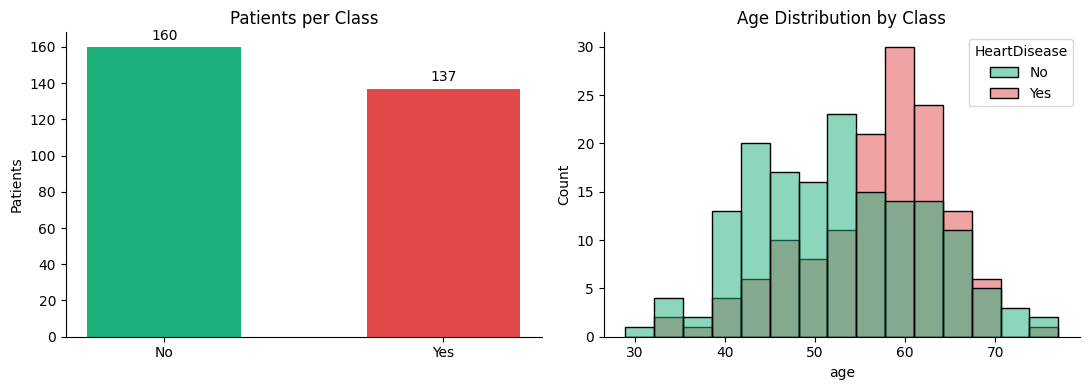

Share of patients with heart disease: 46.1%  ->  the classes are close to balanced.


In [6]:
# ----------------------------------------------------------------------
# EDA 1: Class balance + age distribution of the two classes
# ----------------------------------------------------------------------
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))

class_counts = heart_clean["HeartDisease"].value_counts().reindex(["No", "Yes"])
bars = left.bar(class_counts.index, class_counts.values, color=[NO_COLOUR, YES_COLOUR], width=0.55)
left.bar_label(bars, padding=3)
left.set_title("Patients per Class")
left.set_ylabel("Patients")

sns.histplot(data=heart_clean, x="age", hue="HeartDisease", hue_order=["No", "Yes"],
             palette=[NO_COLOUR, YES_COLOUR], bins=15, multiple="layer", ax=right)
right.set_title("Age Distribution by Class")

for ax in (left, right):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

share_yes = (heart_clean["HeartDisease"] == "Yes").mean()
print(f"Share of patients with heart disease: {share_yes:.1%}  ->  the classes are close to balanced.")

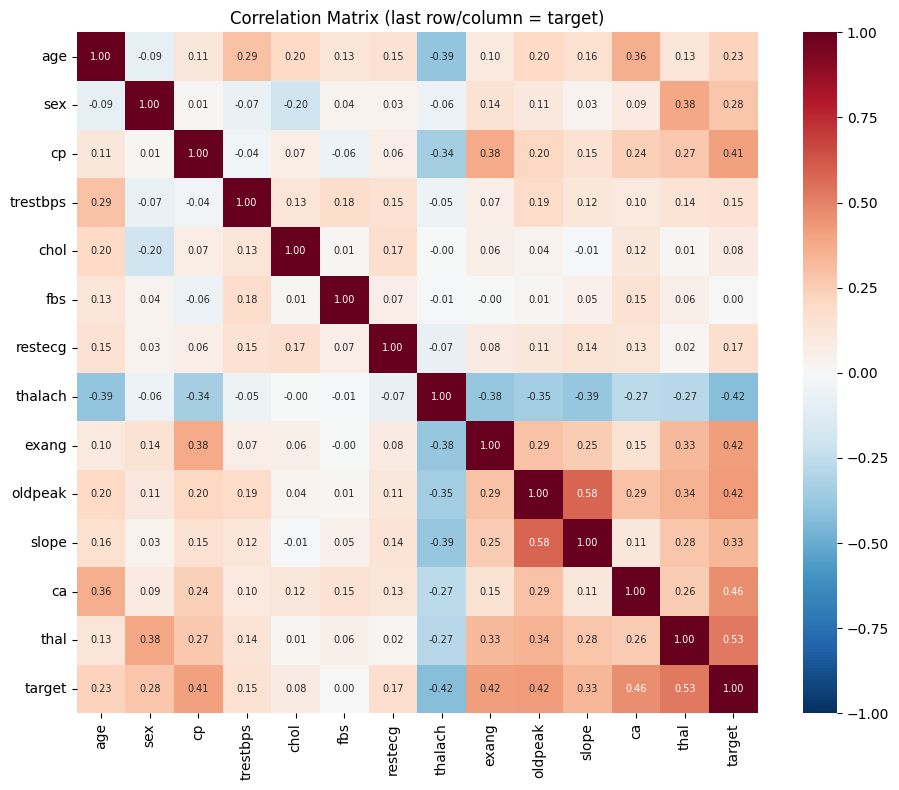

Correlation of each column with the target (strongest first):
thal        0.53
ca          0.46
oldpeak     0.42
thalach     0.42
exang       0.42
cp          0.41
slope       0.33
sex         0.28
age         0.23
restecg     0.17
trestbps    0.15
chol        0.08
fbs         0.00


In [7]:
# ----------------------------------------------------------------------
# EDA 2: Correlation heatmap of all 13 input columns and the target
# ----------------------------------------------------------------------
corr_frame = heart_clean[["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach",
                          "exang", "oldpeak", "slope", "ca", "thal"]].copy()
corr_frame["target"] = (heart_clean["num"] > 0).astype(int)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_frame.corr(), cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7}, square=True)
plt.title("Correlation Matrix (last row/column = target)")
plt.tight_layout()
plt.show()

print("Correlation of each column with the target (strongest first):")
print(corr_frame.corr()["target"].drop("target").abs().sort_values(ascending=False).round(2).to_string())

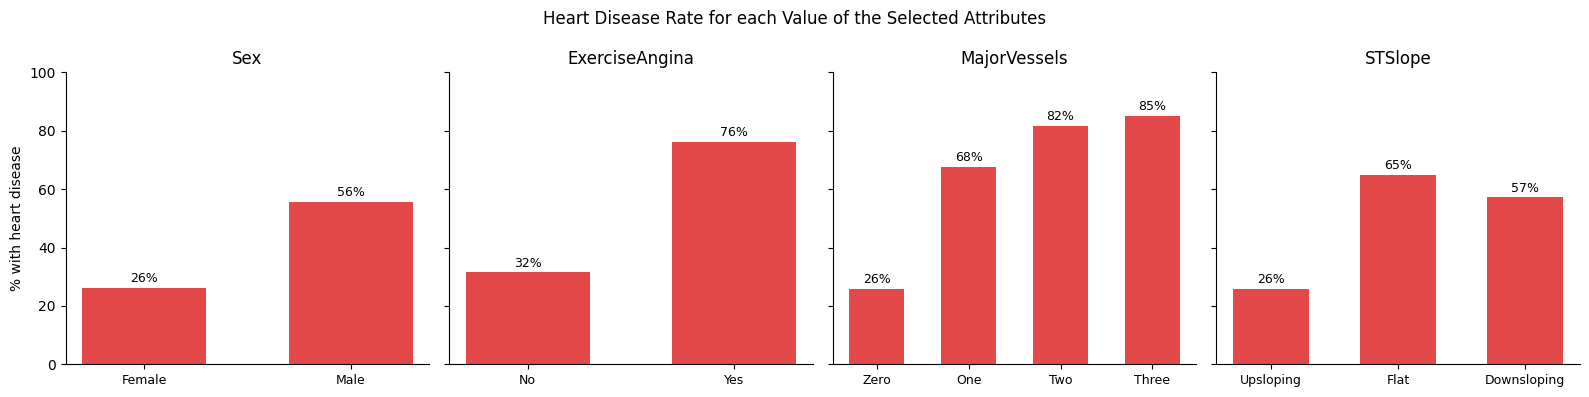

Sex -> {'Male': 201, 'Female': 96}
ExerciseAngina -> {'No': 200, 'Yes': 97}
MajorVessels -> {'Zero': 174, 'One': 65, 'Two': 38, 'Three': 20}
STSlope -> {'Upsloping': 139, 'Flat': 137, 'Downsloping': 21}


In [8]:
# ----------------------------------------------------------------------
# EDA 3: Percentage of patients with heart disease for every value
#        of the 4 selected attributes
# ----------------------------------------------------------------------
attribute_values = {
    "Sex": ["Female", "Male"],
    "ExerciseAngina": ["No", "Yes"],
    "MajorVessels": ["Zero", "One", "Two", "Three"],
    "STSlope": ["Upsloping", "Flat", "Downsloping"],
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, (attribute, values) in zip(axes, attribute_values.items()):
    rate = (heart_clean.groupby(attribute)["HeartDisease"]
            .apply(lambda s: (s == "Yes").mean() * 100).reindex(values))
    bars = ax.bar(values, rate.values, color=YES_COLOUR, width=0.6)
    ax.bar_label(bars, fmt="%.0f%%", padding=2, fontsize=9)
    ax.set_title(attribute)
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", labelsize=9)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("% with heart disease")
plt.suptitle("Heart Disease Rate for each Value of the Selected Attributes")
plt.tight_layout()
plt.show()

for attribute in attribute_values:
    print(attribute, "->", heart_clean[attribute].value_counts().to_dict())

**Observations from the EDA**
- About 46% of patients have heart disease, so the two classes are nearly balanced.
- In the correlation matrix, `thal`, `ca`, `oldpeak`, `exang`, `cp` and `slope` are most related to the target;
  cholesterol and fasting blood sugar are almost unrelated.
- **ExerciseAngina:** patients who feel chest pain during exercise are far more likely to have heart disease.
- **MajorVessels:** the disease rate rises sharply once one or more major vessels are affected.
- **STSlope:** a *flat* or *downsloping* ST segment is linked to a much higher disease rate than an *upsloping* one.
- **Sex:** male patients show a clearly higher disease rate than female patients.
- These four attributes are all categorical (like PClass/Gender/Sibling/Embarked in the Titanic system) and,
  together, give a 10-fold cross-validation accuracy of about 0.83 (Step 7.6).

## Step 4: Feature Extraction / Selection
- The UCI file already contains extracted features, so no feature extraction is needed.
- **Feature selection:** keep only the 4 chosen input attributes — **Sex, ExerciseAngina, MajorVessels, STSlope** —
  plus the output **HeartDisease**.

In [9]:
# ----------------------------------------------------------------------
# Step 4: Keep the 4 inputs + output (output must be the last column)
# ----------------------------------------------------------------------
selected_columns = ["Sex", "ExerciseAngina", "MajorVessels", "STSlope", "HeartDisease"]
sample_data = heart_clean[selected_columns].copy()
sample_data.to_csv("sample-data.csv", index=False)

print("Sample data with the selected attributes (first 8 rows):")
print(sample_data.head(8))
print("\nRecords:", len(sample_data), " | saved to sample-data.csv")

Sample data with the selected attributes (first 8 rows):
      Sex ExerciseAngina MajorVessels      STSlope HeartDisease
0    Male             No         Zero  Downsloping           No
1    Male            Yes        Three         Flat          Yes
2    Male            Yes          Two         Flat          Yes
3    Male             No         Zero  Downsloping           No
4  Female             No         Zero    Upsloping           No
5    Male             No         Zero    Upsloping           No
6  Female             No          Two  Downsloping          Yes
7  Female            Yes         Zero    Upsloping           No

Records: 297  | saved to sample-data.csv


## Step 5: Label Encoding

### Step 5.1: Train the Label Encoders

In [10]:
# ----------------------------------------------------------------------
# Step 5.1: One LabelEncoder per attribute, fitted on the full list of
# possible values (so any valid user input can be encoded later)
# ----------------------------------------------------------------------
sex_encoder = LabelEncoder().fit(["Male", "Female"])
angina_encoder = LabelEncoder().fit(["Yes", "No"])
vessels_encoder = LabelEncoder().fit(["Zero", "One", "Two", "Three"])
slope_encoder = LabelEncoder().fit(["Upsloping", "Flat", "Downsloping"])
target_encoder = LabelEncoder().fit(["Yes", "No"])

encoders = {
    "Sex": sex_encoder,
    "ExerciseAngina": angina_encoder,
    "MajorVessels": vessels_encoder,
    "STSlope": slope_encoder,
    "HeartDisease": target_encoder,
}

mapping_table = PrettyTable(["Attribute", "Value -> Code"])
for attribute, encoder in encoders.items():
    mapping_table.add_row([attribute, ", ".join(f"{v}={int(c)}" for v, c in
                                                zip(encoder.classes_, encoder.transform(encoder.classes_)))])
print(mapping_table)

+----------------+------------------------------------+
|   Attribute    |           Value -> Code            |
+----------------+------------------------------------+
|      Sex       |          Female=0, Male=1          |
| ExerciseAngina |            No=0, Yes=1             |
|  MajorVessels  |   One=0, Three=1, Two=2, Zero=3    |
|    STSlope     | Downsloping=0, Flat=1, Upsloping=2 |
|  HeartDisease  |            No=0, Yes=1             |
+----------------+------------------------------------+


### Step 5.2: Label Encode the Output

In [11]:
# ----------------------------------------------------------------------
# Step 5.2: Encode the output column (No = 0, Yes = 1)
# ----------------------------------------------------------------------
original_sample_data = sample_data.copy()
sample_data_encoded_output = sample_data.copy()
sample_data_encoded_output["HeartDisease"] = target_encoder.transform(sample_data["HeartDisease"])

print("Output before and after encoding (first 8 rows):")
print(pd.DataFrame({"HeartDisease": sample_data["HeartDisease"],
                    "Encoded": sample_data_encoded_output["HeartDisease"]}).head(8))

sample_data_encoded_output.to_csv("sample-data-encoded-output.csv", index=False)
print("\nSaved: sample-data-encoded-output.csv")

Output before and after encoding (first 8 rows):
  HeartDisease  Encoded
0           No        0
1          Yes        1
2          Yes        1
3           No        0
4           No        0
5           No        0
6          Yes        1
7           No        0

Saved: sample-data-encoded-output.csv


### Step 5.3: Label Encode the Input

In [12]:
# ----------------------------------------------------------------------
# Step 5.3: Encode the 4 input columns
# ----------------------------------------------------------------------
sample_data_encoded = sample_data_encoded_output.copy()
for attribute in ["Sex", "ExerciseAngina", "MajorVessels", "STSlope"]:
    sample_data_encoded[attribute] = encoders[attribute].transform(sample_data_encoded_output[attribute])

print("Fully encoded sample data (first 8 rows):")
print(sample_data_encoded.head(8))

sample_data_encoded.to_csv("sample-data-encoded.csv", index=False)
print("\nSaved: sample-data-encoded.csv")

Fully encoded sample data (first 8 rows):
   Sex  ExerciseAngina  MajorVessels  STSlope  HeartDisease
0    1               0             3        0             0
1    1               1             1        1             1
2    1               1             2        1             1
3    1               0             3        0             0
4    0               0             3        2             0
5    1               0             3        2             0
6    0               0             2        0             1
7    0               1             3        2             0

Saved: sample-data-encoded.csv


## Step 6: Training Phase

### Step 6.1: Split Sample Data into Training Data and Testing Data
80% of the records are used for training and 20% for testing. The split is shuffled and **stratified**
on the output, so both parts have the same proportion of Yes/No patients; `random_state=42` makes it repeatable.

In [13]:
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded,
    test_size=0.20,
    random_state=42,
    shuffle=True,
    stratify=sample_data_encoded["HeartDisease"],
)

training_data_encoded.to_csv("training-data-encoded.csv", index=False)
testing_data_encoded.to_csv("testing-data-encoded.csv", index=False)

print("Training data:", training_data_encoded.shape, "->", training_data_encoded["HeartDisease"].value_counts().to_dict())
print("Testing data :", testing_data_encoded.shape, "->", testing_data_encoded["HeartDisease"].value_counts().to_dict())

Training data: (237, 5) -> {0: 128, 1: 109}
Testing data : (60, 5) -> {0: 32, 1: 28}


### Step 6.2: Split Input Vectors and Output Labels of Training Data

In [14]:
X_train = training_data_encoded.iloc[:, :-1]   # all columns except the last -> inputs
y_train = training_data_encoded.iloc[:, -1]    # last column -> output

print("X_train:", X_train.shape, " y_train:", y_train.shape)

X_train: (237, 4)  y_train: (237,)


### Step 6.3: Train the Support Vector Classifier

In [15]:
# SVC with an RBF kernel (scikit-learn default) - same settings as the Titanic system
heart_svc = svm.SVC(gamma="auto", random_state=0)
heart_svc.fit(X_train, np.ravel(y_train))

print("Trained model:", heart_svc)
print("Number of support vectors per class:", heart_svc.n_support_)

Trained model: SVC(gamma='auto', random_state=0)
Number of support vectors per class: [66 64]


### Step 6.4: Save the Trained Model

In [16]:
with open("heart_disease_model.pkl", "wb") as f:
    pickle.dump(heart_svc, f)

print("Model saved to heart_disease_model.pkl")

Model saved to heart_disease_model.pkl


## Step 7: Testing Phase

### Step 7.1: Split Input Vectors and Output Labels of Testing Data

In [17]:
X_test = testing_data_encoded.iloc[:, :-1]
y_test = testing_data_encoded.iloc[:, -1]

print("X_test:", X_test.shape, " y_test:", y_test.shape)

X_test: (60, 4)  y_test: (60,)


### Step 7.2: Load the Saved Model

In [18]:
with open("heart_disease_model.pkl", "rb") as f:
    loaded_model = pickle.load(f)

print("Loaded:", loaded_model)

Loaded: SVC(gamma='auto', random_state=0)


### Step 7.3: Make Predictions on Testing Data

In [19]:
model_predictions = testing_data_encoded.copy()
model_predictions["Predictions"] = loaded_model.predict(X_test)
model_predictions.to_csv("model-predictions.csv", index=False)

print("Actual vs predicted (first 12 test records):")
print(model_predictions.head(12))
print("\nSaved: model-predictions.csv")

Actual vs predicted (first 12 test records):
     Sex  ExerciseAngina  MajorVessels  STSlope  HeartDisease  Predictions
290    1               0             3        2             0            0
239    0               0             3        2             0            0
89     1               0             3        1             0            0
101    0               0             0        2             0            0
67     1               0             3        2             0            0
252    0               0             3        1             0            0
23     1               0             2        2             1            1
235    0               0             3        1             0            0
66     1               0             3        1             1            0
197    0               0             3        2             0            0
192    1               1             2        1             1            1
167    0               0             3        1        

### Step 7.4: Calculate the Accuracy Score

In [20]:
test_accuracy = accuracy_score(model_predictions["HeartDisease"], model_predictions["Predictions"])

print("Accuracy on testing data:", round(test_accuracy, 2))
print(f"Correct predictions: {(model_predictions['HeartDisease'] == model_predictions['Predictions']).sum()}"
      f" out of {len(model_predictions)}")

Accuracy on testing data: 0.9
Correct predictions: 54 out of 60


### Step 7.5: Detailed Evaluation (Precision, Recall, F1-score, Confusion Matrix)

                  precision    recall  f1-score   support

No Heart Disease       0.86      0.97      0.91        32
   Heart Disease       0.96      0.82      0.88        28

        accuracy                           0.90        60
       macro avg       0.91      0.90      0.90        60
    weighted avg       0.91      0.90      0.90        60



True Negatives: 31 | False Positives: 1 | False Negatives: 5 | True Positives: 23


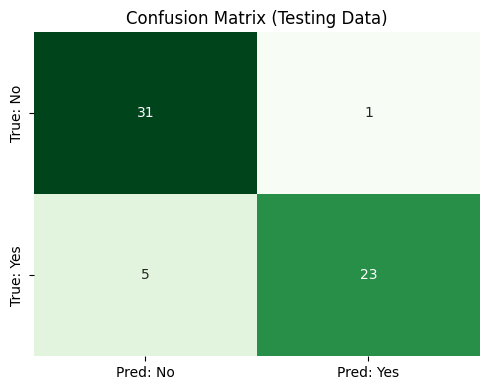

In [21]:
print(classification_report(model_predictions["HeartDisease"], model_predictions["Predictions"],
                            target_names=["No Heart Disease", "Heart Disease"]))

cm = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"])
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives: {tn} | False Positives: {fp} | False Negatives: {fn} | True Positives: {tp}")

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False,
            xticklabels=["Pred: No", "Pred: Yes"], yticklabels=["True: No", "True: Yes"])
plt.title("Confusion Matrix (Testing Data)")
plt.tight_layout()
plt.show()

### Step 7.6: 10-Fold Cross Validation

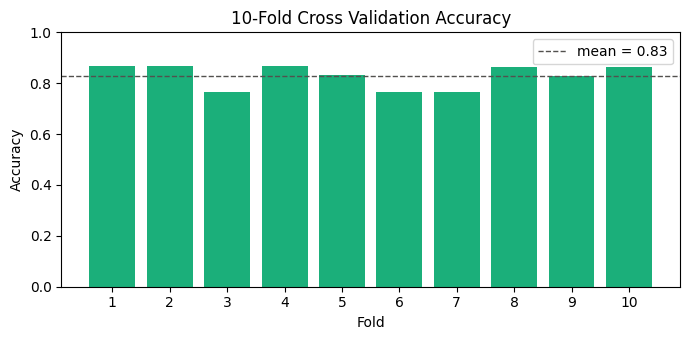

Fold accuracies: [0.87 0.87 0.77 0.87 0.83 0.77 0.77 0.86 0.83 0.86]
Mean: 0.83   Std: 0.04


In [22]:
# A single 60-record test set is small, so the accuracy is also checked with
# 10-fold cross validation on all records.
fold_scores = cross_val_score(svm.SVC(gamma="auto", random_state=0),
                              sample_data_encoded.iloc[:, :-1], sample_data_encoded.iloc[:, -1], cv=10)

plt.figure(figsize=(7, 3.5))
plt.bar(range(1, 11), fold_scores, color=NO_COLOUR)
plt.axhline(fold_scores.mean(), color="#52514e", linestyle="--", linewidth=1,
            label=f"mean = {fold_scores.mean():.2f}")
plt.xticks(range(1, 11))
plt.ylim(0, 1)
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.title("10-Fold Cross Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

print("Fold accuracies:", np.round(fold_scores, 2))
print(f"Mean: {fold_scores.mean():.2f}   Std: {fold_scores.std():.2f}")

## Step 8: Application Phase

### Step 8.1: Take Input from User

In [23]:
# Demo values are used so the notebook runs without typing.
# For live input, replace the four lines with input(), for example:
#   sex_value = input("Sex (Male/Female): ").strip()
#   angina_value = input("Exercise induced angina (Yes/No): ").strip()
#   vessels_value = input("Major vessels (Zero/One/Two/Three): ").strip()
#   slope_value = input("ST slope (Upsloping/Flat/Downsloping): ").strip()
sex_value = "Male"
angina_value = "Yes"
vessels_value = "One"
slope_value = "Flat"

print("Sex:", sex_value, "| ExerciseAngina:", angina_value,
      "| MajorVessels:", vessels_value, "| STSlope:", slope_value)

Sex: Male | ExerciseAngina: Yes | MajorVessels: One | STSlope: Flat


### Step 8.2: Convert User Input into a Feature Vector

In [24]:
new_patient = pd.DataFrame([{
    "Sex": sex_value,
    "ExerciseAngina": angina_value,
    "MajorVessels": vessels_value,
    "STSlope": slope_value,
}])
print(new_patient)

    Sex ExerciseAngina MajorVessels STSlope
0  Male            Yes          One    Flat


### Step 8.3: Label Encode the Feature Vector

In [25]:
new_patient_encoded = new_patient.copy()
for attribute in new_patient.columns:
    new_patient_encoded[attribute] = encoders[attribute].transform(new_patient[attribute])
print(new_patient_encoded)

   Sex  ExerciseAngina  MajorVessels  STSlope
0    1               1             0        1


### Step 8.4: Load the Saved Model

In [26]:
with open("heart_disease_model.pkl", "rb") as f:
    application_model = pickle.load(f)
print("Model ready for predictions")

Model ready for predictions


### Step 8.5: Predict and Return the Result to the User

In [27]:
def predict_heart_disease(patient_encoded):
    """Returns 'Yes' or 'No' for one encoded patient record."""
    return target_encoder.inverse_transform(application_model.predict(patient_encoded))[0]

result = predict_heart_disease(new_patient_encoded)

output_table = PrettyTable(["Sex", "ExerciseAngina", "MajorVessels", "STSlope", "Heart Disease?"])
output_table.add_row(list(new_patient.iloc[0]) + [result.upper()])
print(output_table)

+------+----------------+--------------+---------+----------------+
| Sex  | ExerciseAngina | MajorVessels | STSlope | Heart Disease? |
+------+----------------+--------------+---------+----------------+
| Male |      Yes       |     One      |   Flat  |      YES       |
+------+----------------+--------------+---------+----------------+


In [28]:
# Two more example patients, to show both possible outcomes
more_patients = pd.DataFrame([
    {"Sex": "Female", "ExerciseAngina": "No", "MajorVessels": "Zero", "STSlope": "Upsloping"},
    {"Sex": "Male", "ExerciseAngina": "Yes", "MajorVessels": "Two", "STSlope": "Flat"},
])
more_encoded = more_patients.copy()
for attribute in more_patients.columns:
    more_encoded[attribute] = encoders[attribute].transform(more_patients[attribute])

examples_table = PrettyTable(["Sex", "ExerciseAngina", "MajorVessels", "STSlope", "Heart Disease?"])
for i in range(len(more_patients)):
    examples_table.add_row(list(more_patients.iloc[i]) + [predict_heart_disease(more_encoded.iloc[[i]]).upper()])
print(examples_table)

+--------+----------------+--------------+-----------+----------------+
|  Sex   | ExerciseAngina | MajorVessels |  STSlope  | Heart Disease? |
+--------+----------------+--------------+-----------+----------------+
| Female |       No       |     Zero     | Upsloping |       NO       |
|  Male  |      Yes       |     Two      |    Flat   |      YES       |
+--------+----------------+--------------+-----------+----------------+


## Step 9: Feedback Phase

### Step 9.1: Feedback from Users and Domain Experts

In [29]:
feedback = PrettyTable(["Source", "Observation"])
feedback.align = "l"
feedback.max_width = 90
feedback.add_row(["Cardiologist", "Exercise angina and a flat/downsloping ST segment are standard warning signs; "
                                  "the model's use of them is clinically sensible."])
feedback.add_row(["Cardiologist", "Missing a sick patient (false negative) is worse than a false alarm. "
                                  "Recall for the 'Yes' class should be the main metric."])
feedback.add_row(["Test user", "Only four drop-downs make the app quick to use, but age and blood pressure "
                                "are not considered at all."])
print(feedback)

+--------------+--------------------------------------------------------------------------------------------+
| Source       | Observation                                                                                |
+--------------+--------------------------------------------------------------------------------------------+
| Cardiologist | Exercise angina and a flat/downsloping ST segment are standard warning signs; the model's  |
|              | use of them is clinically sensible.                                                        |
| Cardiologist | Missing a sick patient (false negative) is worse than a false alarm. Recall for the 'Yes'  |
|              | class should be the main metric.                                                           |
| Test user    | Only four drop-downs make the app quick to use, but age and blood pressure are not         |
|              | considered at all.                                                                         |
+---------

### Step 9.2: List of Potential Improvements

In [30]:
improvement_list = [
    "Include numeric attributes (age, oldpeak, thalach) after scaling them with StandardScaler",
    "Replace Label Encoding with One-Hot Encoding for attributes without a natural order",
    "Use GridSearchCV to tune C and gamma of the SVC, and compare with Random Forest / Logistic Regression",
    "Set class_weight='balanced' or lower the decision threshold to raise recall for 'Yes'",
    "Train on all four UCI locations (Cleveland, Hungary, Switzerland, VA Long Beach) for more data",
]
for number, item in enumerate(improvement_list, start=1):
    print(f"{number}. {item}")

1. Include numeric attributes (age, oldpeak, thalach) after scaling them with StandardScaler
2. Replace Label Encoding with One-Hot Encoding for attributes without a natural order
3. Use GridSearchCV to tune C and gamma of the SVC, and compare with Random Forest / Logistic Regression
4. Set class_weight='balanced' or lower the decision threshold to raise recall for 'Yes'
5. Train on all four UCI locations (Cleveland, Hungary, Switzerland, VA Long Beach) for more data


### Step 9.3: Improve the Model Based on Feedback

In [31]:
# Plan for the next version: apply the improvements above, repeat Steps 6-7,
# and replace heart_disease_model.pkl only if recall for 'Yes' improves
# without reducing overall accuracy.
print("Next version plan: tuned SVC + more attributes, accepted only if recall(Yes) improves.")

Next version plan: tuned SVC + more attributes, accepted only if recall(Yes) improves.


## Step 10: Cloud Deployment

The saved model is served as a web application on **Streamlit Community Cloud**.

**Live application:** [ADD-STREAMLIT-LINK-HERE](ADD-STREAMLIT-LINK-HERE)

| File | Purpose |
|---|---|
| `streamlit-app/app.py` | Web page: four drop-down inputs, a Predict button, and the result |
| `streamlit-app/requirements.txt` | Libraries installed by Streamlit Cloud |
| `heart_disease_model.pkl` | The trained SVC loaded by the app |

The app rebuilds the same LabelEncoders as Step 5.1 (fitted on the same value lists), so a user's choice is
converted to exactly the same numbers the model was trained with.

**Deployment steps:** push the project to GitHub → sign in at https://share.streamlit.io with GitHub →
*Create app* → select the repository, branch `main`, main file `streamlit-app/app.py` → *Advanced settings*:
Python 3.12 → *Deploy*.

## Conclusion
This notebook rebuilt the Titanic survival pipeline as a **Heart Disease Prediction System** using the UCI
Cleveland data. After removing 6 incomplete records and converting the diagnosis into Yes/No, four categorical
attributes were selected — **Sex, Exercise-Induced Angina, Number of Major Vessels and ST Slope** — and label
encoded. A Support Vector Classifier trained on 80% of the data reached an **accuracy of 0.90** on the 20% test
set, and **0.83** on average in 10-fold cross validation, which is the more reliable estimate. The model was
saved as `heart_disease_model.pkl`, used to predict new patients, and deployed on Streamlit Community Cloud.